In [88]:
### Homework 5 Code - Karann Singam - 801285554 ###

import torch
import matplotlib.pyplot as plt
from google.colab import drive
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

Non-Linear Model:
  (Learning Rate = 0.1)
    Epoch = 500, Loss = 2.090720
    Epoch = 1000, Loss = 2.090720
    Epoch = 1500, Loss = 2.090720
    Epoch = 2000, Loss = 2.090720
    Epoch = 2500, Loss = 2.090720
    Epoch = 3000, Loss = 2.090720
    Epoch = 3500, Loss = 2.090720
    Epoch = 4000, Loss = 2.090720
    Epoch = 4500, Loss = 2.090720
    Epoch = 5000, Loss = 2.090720
  (Learning Rate = 0.01)
    Epoch = 500, Loss = 2.092286
    Epoch = 1000, Loss = 2.090720
    Epoch = 1500, Loss = 2.090719
    Epoch = 2000, Loss = 2.090719
    Epoch = 2500, Loss = 2.090719
    Epoch = 3000, Loss = 2.090719
    Epoch = 3500, Loss = 2.090719
    Epoch = 4000, Loss = 2.090719
    Epoch = 4500, Loss = 2.090719
    Epoch = 5000, Loss = 2.090719
  (Learning Rate = 0.001)
    Epoch = 500, Loss = 25.740374
    Epoch = 1000, Loss = 8.287434
    Epoch = 1500, Loss = 3.992266
    Epoch = 2000, Loss = 2.734116
    Epoch = 2500, Loss = 2.320184
    Epoch = 3000, Loss = 2.174658
    Epoch = 3500, Loss = 

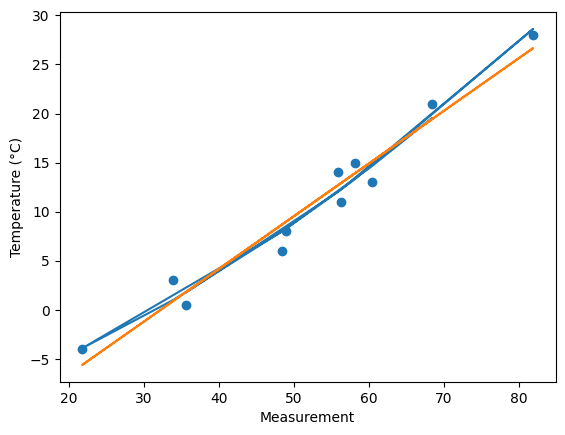

In [89]:
### Problem 1 ###

# Data

t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

# Normalization

t_un = (t_u - t_u.mean()) / t_u.std()

# Models

def non_linear_model(t_u, w1, w2, b):
  return (w2 * t_u ** 2) + (w1 * t_u) + b

def linear_model(t_u, w, b):
  return (w * t_u) + b

# Loss Function

def loss_fn(t_p, t_c):
  squared_diffs = (t_p - t_c) ** 2
  return squared_diffs.mean()

# Training Loops

def non_linear_training_loop(n_epochs, learning_rate):
  params = torch.tensor([1.0, 1.0, 0.0], requires_grad = True)
  optimizer = torch.optim.SGD([params], lr = learning_rate)

  for epoch in range(1, n_epochs + 1):
    t_p = non_linear_model(t_un, params[0], params[1], params[2])
    loss = loss_fn(t_p, t_c)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
      print("    Epoch = %d, Loss = %f" % (epoch, float(loss)))

  return params

def linear_training_loop(n_epochs, learning_rate):
  params = torch.tensor([1.0, 0.0], requires_grad = True)
  optimizer = torch.optim.SGD([params], lr = learning_rate)

  for epoch in range(1, n_epochs + 1):
    t_p = linear_model(t_un, params[0], params[1])
    loss = loss_fn(t_p, t_c)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
      print("    Epoch = %d, Loss = %f" % (epoch, float(loss)))

  return params

# Running Both Models

non_linear_best_loss = float('inf')
non_linear_best_params = []

print("Non-Linear Model:")
for learning_rate in [0.1, 0.01, 0.001, 0.0001]:
  print(f"  (Learning Rate = {learning_rate})")

  temp = non_linear_training_loop(
      n_epochs = 5000,
      learning_rate = learning_rate
  )

  final_loss = loss_fn(non_linear_model(t_un, temp[0], temp[1], temp[2]), t_c)
  if final_loss < non_linear_best_loss:
    non_linear_best_loss = final_loss
    non_linear_best_params = temp

linear_best_loss = float('inf')
linear_best_params = []

print("\nLinear Model:")
for learning_rate in [0.1, 0.01, 0.001, 0.0001]:
  print(f"  (Learning Rate = {learning_rate})")

  temp = linear_training_loop(
      n_epochs = 5000,
      learning_rate = learning_rate
  )

  final_loss = loss_fn(linear_model(t_un, temp[0], temp[1]), t_c)
  if final_loss < linear_best_loss:
    linear_best_loss = final_loss
    linear_best_params = temp

print("\nBest Non-Linear Loss =", float(non_linear_best_loss))
print("Best Linear Loss =", float(linear_best_loss), "\n")

# Plotting Graph

plt.figure()
plt.scatter(t_u, t_c)
plt.plot(t_u, non_linear_model(t_un, non_linear_best_params[0], non_linear_best_params[1], non_linear_best_params[2]).detach())
plt.plot(t_u, linear_model(t_un, linear_best_params[0], linear_best_params[1]).detach())
plt.xlabel("Measurement")
plt.ylabel("Temperature (°C)")
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

(Learning Rate = 0.1)
  Epoch = 500, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 1000, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 1500, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 2000, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 2500, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 3000, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 3500, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742


/tmp/ipykernel_1195/1347983972.py:14: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace({"no": 0, "yes": 1})
/tmp/ipykernel_1195/1347983972.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace({"unfurnished": 0, "semi-furnished": 1, "furnished": 2})


  Epoch = 4000, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 4500, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 5000, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742


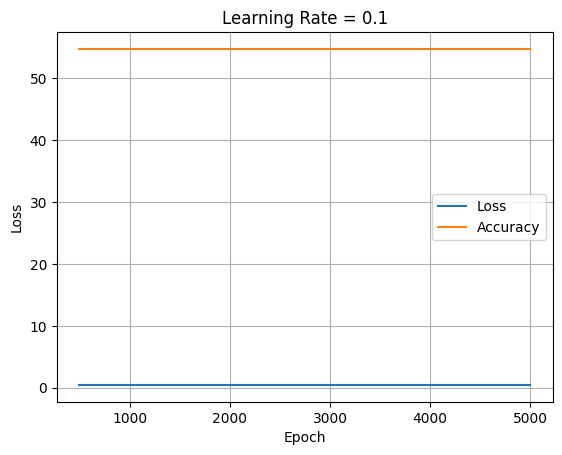


(Learning Rate = 0.01)
  Epoch = 500, Training Loss = 0.437555, Validation Loss = 0.458852, Validation Accuracy = 54.776530
  Epoch = 1000, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765765
  Epoch = 1500, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 2000, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 2500, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 3000, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 3500, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 4000, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 4500, Training Loss = 0.437555, Validation Loss = 0.458961, Validation Accuracy = 54.765742
  Epoch = 5000, Training Loss = 0.437555, Validation Loss =

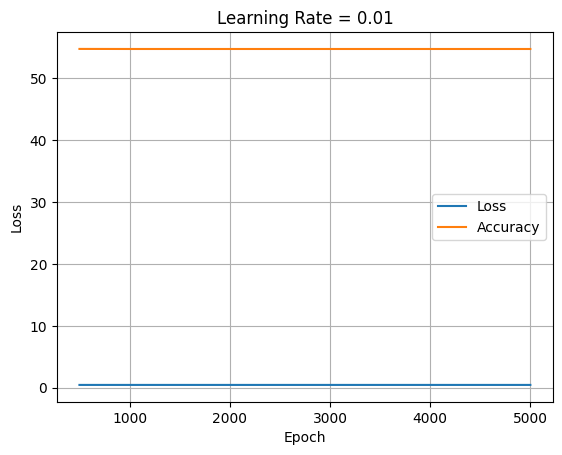


(Learning Rate = 0.001)
  Epoch = 500, Training Loss = 0.465264, Validation Loss = 0.453590, Validation Accuracy = 55.295130
  Epoch = 1000, Training Loss = 0.441967, Validation Loss = 0.445079, Validation Accuracy = 56.133918
  Epoch = 1500, Training Loss = 0.438702, Validation Loss = 0.450449, Validation Accuracy = 55.604697
  Epoch = 2000, Training Loss = 0.437882, Validation Loss = 0.454199, Validation Accuracy = 55.235120
  Epoch = 2500, Training Loss = 0.437651, Validation Loss = 0.456372, Validation Accuracy = 55.020923
  Epoch = 3000, Training Loss = 0.437583, Validation Loss = 0.457571, Validation Accuracy = 54.902810
  Epoch = 3500, Training Loss = 0.437563, Validation Loss = 0.458218, Validation Accuracy = 54.839008
  Epoch = 4000, Training Loss = 0.437557, Validation Loss = 0.458565, Validation Accuracy = 54.804854
  Epoch = 4500, Training Loss = 0.437556, Validation Loss = 0.458749, Validation Accuracy = 54.786635
  Epoch = 5000, Training Loss = 0.437555, Validation Loss 

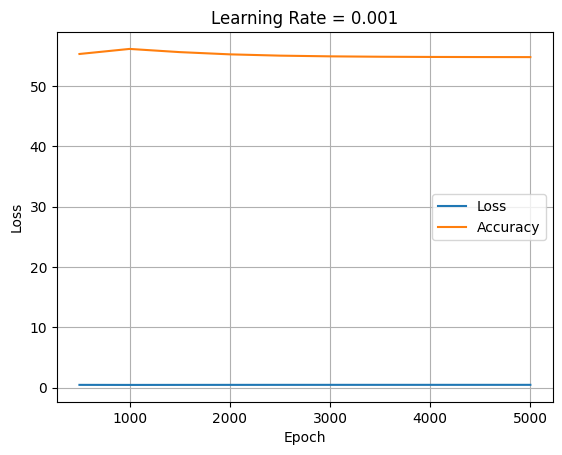


(Learning Rate = 0.0001)
  Epoch = 500, Training Loss = 0.835979, Validation Loss = 0.840849, Validation Accuracy = 17.127705
  Epoch = 1000, Training Loss = 0.721526, Validation Loss = 0.716601, Validation Accuracy = 29.373297
  Epoch = 1500, Training Loss = 0.641570, Validation Loss = 0.630716, Validation Accuracy = 37.837978
  Epoch = 2000, Training Loss = 0.585478, Validation Loss = 0.571337, Validation Accuracy = 43.690227
  Epoch = 2500, Training Loss = 0.545930, Validation Loss = 0.530295, Validation Accuracy = 47.735278
  Epoch = 3000, Training Loss = 0.517879, Validation Loss = 0.501953, Validation Accuracy = 50.528536
  Epoch = 3500, Training Loss = 0.497844, Validation Loss = 0.482422, Validation Accuracy = 52.453483
  Epoch = 4000, Training Loss = 0.483418, Validation Loss = 0.469012, Validation Accuracy = 53.775204
  Epoch = 4500, Training Loss = 0.472933, Validation Loss = 0.459860, Validation Accuracy = 54.677194
  Epoch = 5000, Training Loss = 0.465233, Validation Loss

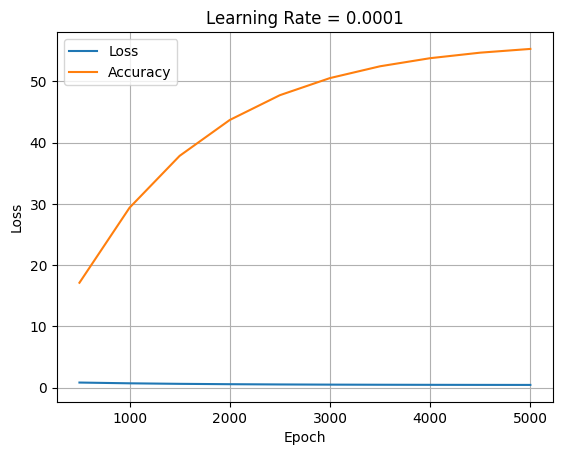


Best Loss = 0.453675972834594
Best Accuracy = 55.286663936363766


In [90]:
### Problem 2 ###

# Epochs

n_epochs = 5000

# Mounting Drive and Reading CSV File

drive.mount("/content/drive")
df = pd.read_csv("/content/drive/MyDrive/ECGR_4105/Datasets/Housing.csv")

# Initializing Variables

df = df.replace({"no": 0, "yes": 1})
df = df.replace({"unfurnished": 0, "semi-furnished": 1, "furnished": 2})
X = df[["area", "bedrooms", "bathrooms", "stories", "parking"]]
Y = df["price"]

# Preprocessing

XT, XV, YT, YV = train_test_split(X, Y, train_size = 0.8, test_size = 0.2, random_state = 100)

scaler = StandardScaler()
XT = scaler.fit_transform(XT)
XV = scaler.transform(XV)

scaler = StandardScaler()
YT = scaler.fit_transform(YT.values.reshape(-1, 1)).flatten()
YV = scaler.transform(YV.values.reshape(-1, 1)).flatten()

# Training Loop

def regression_training_loop(n_epochs, learning_rate):
  theta = np.zeros(6) # 5 weights and 1 bias
  n = XT.shape[0]

  training_losses = []
  validation_losses = []
  validation_accuracies = []

  for epoch in range(1, n_epochs + 1):
    HT = theta[0] + (theta[1] * XT[:, 0]) + (theta[2] * XT[:, 1]) + (theta[3] * XT[:, 2]) + (theta[4] * XT[:, 3]) + (theta[5] * XT[:, 4])
    training_loss = np.mean((HT - YT) ** 2)

    d_theta_0 = (2 / n) * np.sum(HT - YT)
    d_theta_1 = (2 / n) * np.sum((HT - YT) * XT[:, 0])
    d_theta_2 = (2 / n) * np.sum((HT - YT) * XT[:, 1])
    d_theta_3 = (2 / n) * np.sum((HT - YT) * XT[:, 2])
    d_theta_4 = (2 / n) * np.sum((HT - YT) * XT[:, 3])
    d_theta_5 = (2 / n) * np.sum((HT - YT) * XT[:, 4])

    theta[0] = theta[0] - (learning_rate * d_theta_0)
    theta[1] = theta[1] - (learning_rate * d_theta_1)
    theta[2] = theta[2] - (learning_rate * d_theta_2)
    theta[3] = theta[3] - (learning_rate * d_theta_3)
    theta[4] = theta[4] - (learning_rate * d_theta_4)
    theta[5] = theta[5] - (learning_rate * d_theta_5)

    if epoch % 500 == 0:
      HV = theta[0] + (theta[1] * XV[:, 0]) + (theta[2] * XV[:, 1]) + (theta[3] * XV[:, 2]) + (theta[4] * XV[:, 3]) + (theta[5] * XV[:, 4])

      validation_loss = np.mean((HV - YV) ** 2)
      validation_accuracy = 100 * r2_score(YV, HV)

      training_losses.append(training_loss)
      validation_losses.append(validation_loss)
      validation_accuracies.append(validation_accuracy)

      print("  Epoch = %d, Training Loss = %f, Validation Loss = %f, Validation Accuracy = %f" % (epoch, float(training_loss), float(validation_loss), float(validation_accuracy)))

  return validation_losses, validation_accuracies

# Running Regression

best_validation_loss = float('inf')

for learning_rate in [0.1, 0.01, 0.001, 0.0001]:
  print(f"\n(Learning Rate = {learning_rate})")

  validation_losses, validation_accuracies = regression_training_loop(
      n_epochs = n_epochs,
      learning_rate = learning_rate
  )

  if validation_losses[-1] < best_validation_loss:
    best_validation_loss = validation_losses[-1]
    best_validation_accuracy = validation_accuracies[-1]

  # Plotting Graph
  epoch_separation = list(range(500, n_epochs + 1, 500))
  plt.figure()
  plt.plot(epoch_separation, validation_losses, label = "Loss")
  plt.plot(epoch_separation, validation_accuracies, label = "Accuracy")
  plt.title(f"Learning Rate = {learning_rate}")
  plt.xlabel("Epoch")
  plt.ylabel("Loss")
  plt.legend()
  plt.grid()
  plt.show()

print("\nBest Loss =", float(best_validation_loss))
print("Best Accuracy =", float(best_validation_accuracy))



(Learning Rate = 0.1)
  Epoch = 500, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 1000, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 1500, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 2000, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 2500, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 3000, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 3500, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 4000, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 4500, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 5000, Training Loss = 0.322668, Validation Loss = 

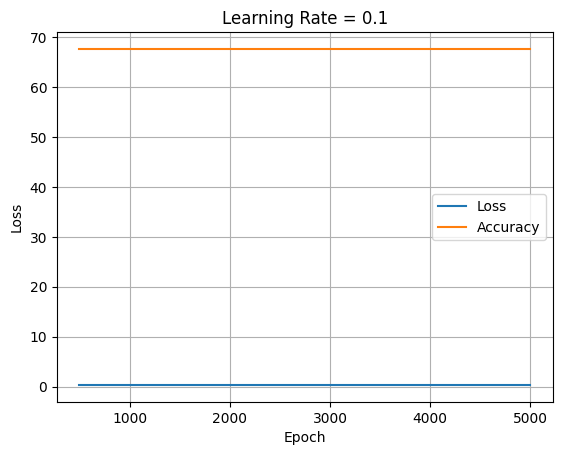


(Learning Rate = 0.01)
  Epoch = 500, Training Loss = 0.322668, Validation Loss = 0.328493, Validation Accuracy = 67.624415
  Epoch = 1000, Training Loss = 0.322668, Validation Loss = 0.328408, Validation Accuracy = 67.632822
  Epoch = 1500, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633086
  Epoch = 2000, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 2500, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 3000, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 3500, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 4000, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 4500, Training Loss = 0.322668, Validation Loss = 0.328405, Validation Accuracy = 67.633091
  Epoch = 5000, Training Loss = 0.322668, Validation Loss =

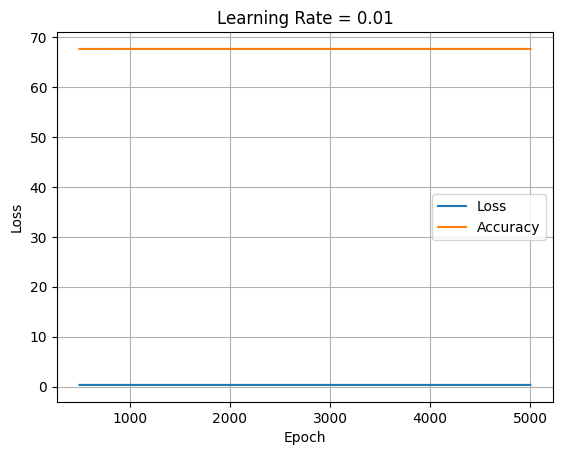


(Learning Rate = 0.001)
  Epoch = 500, Training Loss = 0.337933, Validation Loss = 0.322729, Validation Accuracy = 68.192542
  Epoch = 1000, Training Loss = 0.325405, Validation Loss = 0.323434, Validation Accuracy = 68.123031
  Epoch = 1500, Training Loss = 0.323454, Validation Loss = 0.325875, Validation Accuracy = 67.882408
  Epoch = 2000, Training Loss = 0.322914, Validation Loss = 0.327258, Validation Accuracy = 67.746104
  Epoch = 2500, Training Loss = 0.322750, Validation Loss = 0.327983, Validation Accuracy = 67.674672
  Epoch = 3000, Training Loss = 0.322697, Validation Loss = 0.328325, Validation Accuracy = 67.640973
  Epoch = 3500, Training Loss = 0.322679, Validation Loss = 0.328465, Validation Accuracy = 67.627142
  Epoch = 4000, Training Loss = 0.322672, Validation Loss = 0.328508, Validation Accuracy = 67.622919
  Epoch = 4500, Training Loss = 0.322669, Validation Loss = 0.328508, Validation Accuracy = 67.622905
  Epoch = 5000, Training Loss = 0.322668, Validation Loss 

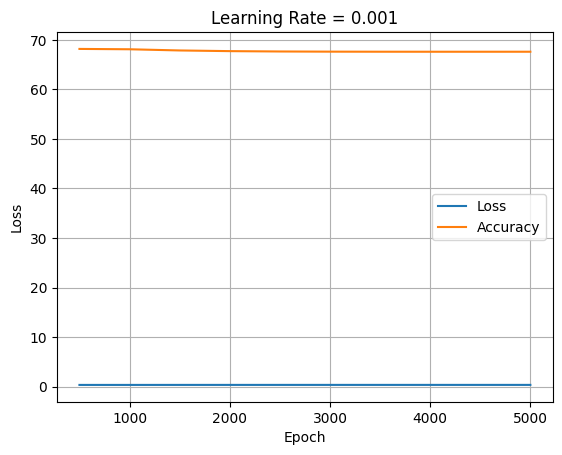


(Learning Rate = 0.0001)
  Epoch = 500, Training Loss = 0.753092, Validation Loss = 0.744136, Validation Accuracy = 26.659590
  Epoch = 1000, Training Loss = 0.598209, Validation Loss = 0.575109, Validation Accuracy = 43.318451
  Epoch = 1500, Training Loss = 0.500998, Validation Loss = 0.472198, Validation Accuracy = 53.461166
  Epoch = 2000, Training Loss = 0.439727, Validation Loss = 0.409859, Validation Accuracy = 59.605197
  Epoch = 2500, Training Loss = 0.400889, Validation Loss = 0.372352, Validation Accuracy = 63.301745
  Epoch = 3000, Training Loss = 0.376080, Validation Loss = 0.349997, Validation Accuracy = 65.505090
  Epoch = 3500, Training Loss = 0.360072, Validation Loss = 0.336846, Validation Accuracy = 66.801137
  Epoch = 4000, Training Loss = 0.349606, Validation Loss = 0.329261, Validation Accuracy = 67.548739
  Epoch = 4500, Training Loss = 0.342648, Validation Loss = 0.325017, Validation Accuracy = 67.967022
  Epoch = 5000, Training Loss = 0.337927, Validation Loss

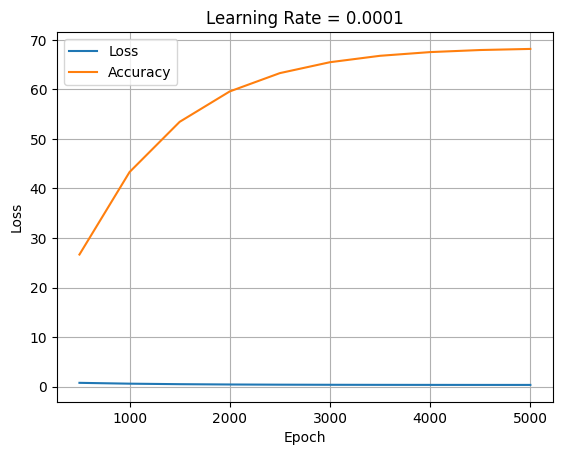


Best Loss = 0.3227617604007457
Best Accuracy = 68.18928943686629


In [91]:
### Problem 3 ###

# Epochs

n_epochs = 5000

# Initializing Variables

X = df[["area", "bedrooms", "bathrooms", "stories", "mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "parking", "prefarea", "furnishingstatus"]]

# Preprocessing

XT, XV, YT, YV = train_test_split(X, Y, train_size = 0.8, test_size = 0.2, random_state = 100)

scaler = StandardScaler()
XT = scaler.fit_transform(XT)
XV = scaler.transform(XV)

scaler = StandardScaler()
YT = scaler.fit_transform(YT.values.reshape(-1, 1)).flatten()
YV = scaler.transform(YV.values.reshape(-1, 1)).flatten()

# Training Loop

def regression_training_loop_2(n_epochs, learning_rate):
  theta = np.zeros(13) # 12 weights and 1 bias
  n = XT.shape[0]

  training_losses = []
  validation_losses = []
  validation_accuracies = []

  for epoch in range(1, n_epochs + 1):
    HT = theta[0] + (theta[1] * XT[:, 0]) + (theta[2] * XT[:, 1]) + (theta[3] * XT[:, 2]) + (theta[4] * XT[:, 3]) + (theta[5] * XT[:, 4]) + (theta[6] * XT[:, 5]) + (theta[7] * XT[:, 6]) + (theta[8] * XT[:, 7]) + (theta[9] * XT[:, 8]) + (theta[10] * XT[:, 9]) + (theta[11] * XT[:, 10]) + (theta[12] * XT[:, 11])
    training_loss = np.mean((HT - YT) ** 2)

    d_theta_0 = (2 / n) * np.sum(HT - YT)
    d_theta_1 = (2 / n) * np.sum((HT - YT) * XT[:, 0])
    d_theta_2 = (2 / n) * np.sum((HT - YT) * XT[:, 1])
    d_theta_3 = (2 / n) * np.sum((HT - YT) * XT[:, 2])
    d_theta_4 = (2 / n) * np.sum((HT - YT) * XT[:, 3])
    d_theta_5 = (2 / n) * np.sum((HT - YT) * XT[:, 4])
    d_theta_6 = (2 / n) * np.sum((HT - YT) * XT[:, 5])
    d_theta_7 = (2 / n) * np.sum((HT - YT) * XT[:, 6])
    d_theta_8 = (2 / n) * np.sum((HT - YT) * XT[:, 7])
    d_theta_9 = (2 / n) * np.sum((HT - YT) * XT[:, 8])
    d_theta_10 = (2 / n) * np.sum((HT - YT) * XT[:, 9])
    d_theta_11 = (2 / n) * np.sum((HT - YT) * XT[:, 10])
    d_theta_12 = (2 / n) * np.sum((HT - YT) * XT[:, 11])

    theta[0] = theta[0] - (learning_rate * d_theta_0)
    theta[1] = theta[1] - (learning_rate * d_theta_1)
    theta[2] = theta[2] - (learning_rate * d_theta_2)
    theta[3] = theta[3] - (learning_rate * d_theta_3)
    theta[4] = theta[4] - (learning_rate * d_theta_4)
    theta[5] = theta[5] - (learning_rate * d_theta_5)
    theta[6] = theta[6] - (learning_rate * d_theta_6)
    theta[7] = theta[7] - (learning_rate * d_theta_7)
    theta[8] = theta[8] - (learning_rate * d_theta_8)
    theta[9] = theta[9] - (learning_rate * d_theta_9)
    theta[10] = theta[10] - (learning_rate * d_theta_10)
    theta[11] = theta[11] - (learning_rate * d_theta_11)
    theta[12] = theta[12] - (learning_rate * d_theta_12)

    if epoch % 500 == 0:
      HV = theta[0] + (theta[1] * XV[:, 0]) + (theta[2] * XV[:, 1]) + (theta[3] * XV[:, 2]) + (theta[4] * XV[:, 3]) + (theta[5] * XV[:, 4]) + (theta[6] * XV[:, 5]) + (theta[7] * XV[:, 6]) + (theta[8] * XV[:, 7]) + (theta[9] * XV[:, 8]) + (theta[10] * XV[:, 9]) + (theta[11] * XV[:, 10]) + (theta[12] * XV[:, 11])

      validation_loss = np.mean((HV - YV) ** 2)
      validation_accuracy = 100 * r2_score(YV, HV)

      training_losses.append(training_loss)
      validation_losses.append(validation_loss)
      validation_accuracies.append(validation_accuracy)

      print("  Epoch = %d, Training Loss = %f, Validation Loss = %f, Validation Accuracy = %f" % (epoch, float(training_loss), float(validation_loss), float(validation_accuracy)))

  return validation_losses, validation_accuracies

# Running Regression

best_validation_loss = float('inf')

for learning_rate in [0.1, 0.01, 0.001, 0.0001]:
  print(f"\n(Learning Rate = {learning_rate})")

  validation_losses, validation_accuracies = regression_training_loop_2(
      n_epochs = n_epochs,
      learning_rate = learning_rate
  )

  if validation_losses[-1] < best_validation_loss:
    best_validation_loss = validation_losses[-1]
    best_validation_accuracy = validation_accuracies[-1]

  # Plotting Graph
  epoch_separation = list(range(500, n_epochs + 1, 500))
  plt.figure()
  plt.plot(epoch_separation, validation_losses, label = "Loss")
  plt.plot(epoch_separation, validation_accuracies, label = "Accuracy")
  plt.title(f"Learning Rate = {learning_rate}")
  plt.xlabel("Epoch")
  plt.ylabel("Loss")
  plt.legend()
  plt.grid()
  plt.show()

print("\nBest Loss =", float(best_validation_loss))
print("Best Accuracy =", float(best_validation_accuracy))
